<a href="https://colab.research.google.com/github/wonhoyeo-oss/CV2026/blob/main/homework3_graph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.8767 - loss: 0.4487 - val_accuracy: 0.9458 - val_loss: 0.1807
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9501 - loss: 0.1705 - val_accuracy: 0.9683 - val_loss: 0.1202
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9673 - loss: 0.1155 - val_accuracy: 0.9733 - val_loss: 0.0949
Epoch 4/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.9760 - loss: 0.0854 - val_accuracy: 0.9772 - val_loss: 0.0840
Epoch 5/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9812 - loss: 0.0657 - val_accuracy: 0.9778 - val_loss: 0.0782
Epoch 6/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9854 - loss: 0.0521 - val_accuracy: 0.9778 - val_loss: 0.0747
Epoch 7/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9891 - loss: 0.0420 - val_accuracy: 0.9802 - val_loss: 0.0727
Epoch 8/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9914 - loss: 0.0343 - val_accu

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 58s 530ms/step - accuracy: 0.8704 - loss: 0.4572 - val_accuracy: 0.9655 - val_loss: 0.1211
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 59s 544ms/step - accuracy: 0.9671 - loss: 0.1100 - val_accuracy: 0.9798 - val_loss: 0.0733
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 59s 545ms/step - accuracy: 0.9779 - loss: 0.0724 - val_accuracy: 0.9833 - val_loss: 0.0597
Epoch 4/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 82s 542ms/step - accuracy: 0.9830 - loss: 0.0555 - val_accuracy: 0.9843 - val_loss: 0.0527
Epoch 5/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 82s 542ms/step - accuracy: 0.9860 - loss: 0.0462 - val_accuracy: 0.9868 - val_loss: 0.0481
Epoch 6/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 59s 545ms/step - accuracy: 0.9880 - loss: 0.0395 - val_accuracy: 0.9867 - val_loss: 0.0469
Epoch 7/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 80s 528ms/step - accuracy: 0.9900 - loss: 0.0339 - val_accuracy: 0.9868 - val_loss: 0.0464
Epoch 8/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 84s 540ms/step - accuracy: 0.9913 - loss: 0

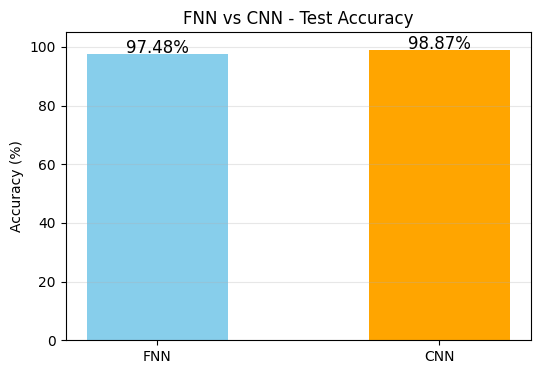

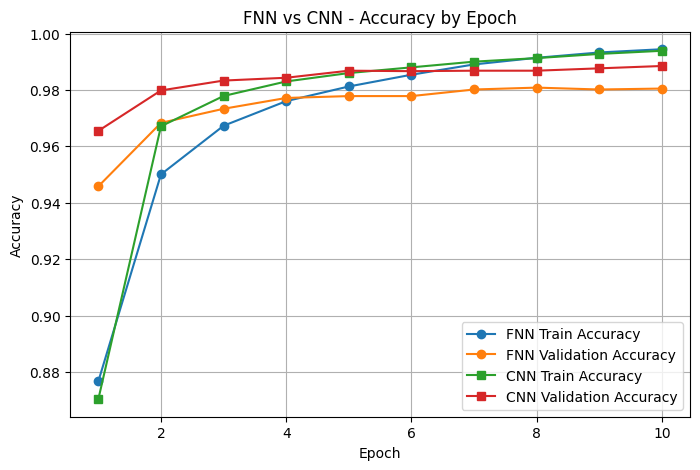

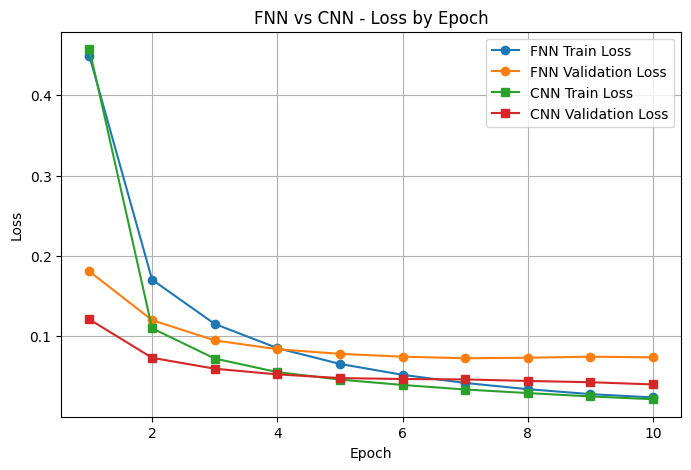

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D

tf.random.set_seed(1)

# 데이터 준비
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255
x_train_cnn = x_train.reshape(-1, 28, 28, 1)
x_test_cnn = x_test.reshape(-1, 28, 28, 1)

EPOCHS, BATCH = 10, 500   # 두 모델 조건을 똑같이

# FNN
fnn = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax'),
])
fnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
h_fnn = fnn.fit(x_train, y_train, epochs=EPOCHS, batch_size=BATCH,
                validation_split=0.1, verbose=1)

# CNN
cnn = Sequential([
    Conv2D(16, (5, 5), activation='relu', padding='same', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(32, (5, 5), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax'),
])
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
h_cnn = cnn.fit(x_train_cnn, y_train, epochs=EPOCHS, batch_size=BATCH,
                validation_split=0.1, verbose=1)

# 테스트 평가
loss_f, acc_f = fnn.evaluate(x_test, y_test, verbose=0)
loss_c, acc_c = cnn.evaluate(x_test_cnn, y_test, verbose=0)
print(f"FNN test acc: {acc_f*100:.2f}%  loss: {loss_f:.4f}  params: {fnn.count_params():,}")
print(f"CNN test acc: {acc_c*100:.2f}%  loss: {loss_c:.4f}  params: {cnn.count_params():,}")

epochs = range(1, EPOCHS + 1)

# 1) 테스트 정확도 막대그래프
plt.figure(figsize=(6, 4))
bars = plt.bar(['FNN', 'CNN'], [acc_f * 100, acc_c * 100], color=['skyblue', 'orange'], width=0.5)
for b, v in zip(bars, [acc_f * 100, acc_c * 100]):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.2f}%", ha='center', fontsize=12)
plt.title('FNN vs CNN - Test Accuracy')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 105)
plt.grid(axis='y', alpha=0.3)
plt.show()

# 2) epoch별 정확도
plt.figure(figsize=(8, 5))
plt.plot(epochs, h_fnn.history['accuracy'], 'o-', label='FNN Train Accuracy')
plt.plot(epochs, h_fnn.history['val_accuracy'], 'o-', label='FNN Validation Accuracy')
plt.plot(epochs, h_cnn.history['accuracy'], 's-', label='CNN Train Accuracy')
plt.plot(epochs, h_cnn.history['val_accuracy'], 's-', label='CNN Validation Accuracy')
plt.title('FNN vs CNN - Accuracy by Epoch')
plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.grid(True); plt.legend()
plt.show()

# 3) epoch별 loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, h_fnn.history['loss'], 'o-', label='FNN Train Loss')
plt.plot(epochs, h_fnn.history['val_loss'], 'o-', label='FNN Validation Loss')
plt.plot(epochs, h_cnn.history['loss'], 's-', label='CNN Train Loss')
plt.plot(epochs, h_cnn.history['val_loss'], 's-', label='CNN Validation Loss')
plt.title('FNN vs CNN - Loss by Epoch')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.grid(True); plt.legend()
plt.show()